# Основная модель (CatBoost)

**Цель:** выбрать финальную конфигурацию градиентного бустинга CatBoost для оценки вероятности дефолта заёмщика. Отложенная выборка `test` изолируется сразу после разбиения и не используется до финальной оценки на шаге 6.

**План работы:**
1. **Признаки `loan_grade` и `loan_int_rate`:** проверка влияния внутренних банковских оценок на качество бустинга.
2. **Способ подачи данных:** сравнение предобработки из линейного бейзлайна с нативной обработкой категориальных признаков и пропусков в CatBoost.
3. **Feature engineering:** конструирование и отбор новых доменных признаков.
4. **Тюнинг гиперпараметров:** подбор оптимальных параметров CatBoost на кросс-валидации.
5. **Калибровка вероятностей и выбор порога:** проверка калибровки предсказываемых вероятностей и подбор рабочего порога отсечения.
6. **Финальная оценка на `test`:** однократная проверка выбранной модели на отложенной выборке.
7. **Интерпретация модели:** анализ важности признаков и вклада факторов риска.

## Шаг 0. Каркас валидации и базовые модели

Фиксируем константы, загружаем очищенные данные, изолируем тестовую выборку и настраиваем единую функцию 5-фолдовой стратифицированной кросс-валидации для честного сравнения всех последующих экспериментов.

In [1]:
import json
import platform
import sys
sys.path.append("..")

from collections.abc import Callable
from typing import Any

import catboost
import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import shap
import sklearn
from catboost import CatBoostClassifier, Pool
from optuna.samplers import TPESampler
from sklearn.base import BaseEstimator
from sklearn.calibration import calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    brier_score_loss,
    confusion_matrix,
    log_loss,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import StratifiedKFold, cross_val_predict, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from src.data import clean, load_raw

optuna.logging.set_verbosity(optuna.logging.WARNING)

RANDOM_STATE = 42
N_SPLITS = 5
TEST_SIZE = 0.2

### Загрузка данных и разбиение на train / test

Загружаем и очищаем датасет функциями из `src/data.py`, после чего выполняем стратифицированное разбиение и откладываем `X_test`, `y_test` до финального шага.

In [2]:
df = clean(load_raw())
print(f"Строк после очистки: {len(df)}, доля дефолтов: {df['loan_status'].mean():.4f}")

Строк после очистки: 32398, доля дефолтов: 0.2188


In [3]:
X = df.drop(columns=["loan_status"])
y = df["loan_status"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE
)

print(f"Train: {X_train.shape[0]} строк, доля дефолтов: {y_train.mean():.4f}")
print(f"Test:  {X_test.shape[0]} строк, доля дефолтов: {y_test.mean():.4f}")

Train: 25918 строк, доля дефолтов: 0.2188
Test:  6480 строк, доля дефолтов: 0.2188


### Метрики и схема кросс-валидации

Определяем функцию расчёта ключевых метрик кредитного скоринга (`ROC-AUC`, `PR-AUC`, `KS`, `Gini`), универсальную функцию 5-fold CV на обучающей выборке и накопительную таблицу результатов.

In [4]:
def compute_metrics(y_true: pd.Series | np.ndarray, y_proba: np.ndarray) -> dict[str, float]:
    """Считает ROC-AUC, PR-AUC, KS-статистику и коэффициент Gini по вероятностям дефолта."""
    roc_auc = float(roc_auc_score(y_true, y_proba))
    pr_auc = float(average_precision_score(y_true, y_proba))
    fpr, tpr, _ = roc_curve(y_true, y_proba)
    ks = float(np.max(tpr - fpr))
    gini = 2.0 * roc_auc - 1.0
    return {
        "ROC-AUC": roc_auc,
        "PR-AUC": pr_auc,
        "KS": ks,
        "Gini": gini,
    }

In [5]:
def run_cv(
    model_factory: Callable[[], BaseEstimator],
    X_data: pd.DataFrame,
    y_data: pd.Series,
    cv_seed: int = RANDOM_STATE,
) -> dict[str, Any]:
    """Выполняет 5-фолдовую стратифицированную кросс-валидацию и возвращает метрики и OOF-вероятности."""
    skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=cv_seed)
    oof_proba = np.zeros(len(y_data), dtype=float)
    fold_rows = []

    for train_idx, val_idx in skf.split(X_data, y_data):
        X_fold_train, X_fold_val = X_data.iloc[train_idx], X_data.iloc[val_idx]
        y_fold_train, y_fold_val = y_data.iloc[train_idx], y_data.iloc[val_idx]

        model = model_factory()
        model.fit(X_fold_train, y_fold_train)
        val_proba = model.predict_proba(X_fold_val)[:, 1]

        oof_proba[val_idx] = val_proba
        fold_rows.append(compute_metrics(y_fold_val, val_proba))

    folds_df = pd.DataFrame(fold_rows)
    return {
        "mean": folds_df.mean().to_dict(),
        "std": folds_df.std().to_dict(),
        "folds": folds_df,
        "oof_proba": oof_proba,
    }

In [6]:
results = pd.DataFrame(columns=["Модель", "ROC-AUC", "PR-AUC", "KS", "Gini"])


def add_result(name: str, cv_output: dict[str, Any]) -> pd.DataFrame:
    """Добавляет строку со средними и стандартными отклонениями метрик по фолдам в таблицу results."""
    global results
    row = {"Модель": name}
    for metric in ["ROC-AUC", "PR-AUC", "KS", "Gini"]:
        mean_val = cv_output["mean"][metric]
        std_val = cv_output["std"][metric]
        row[metric] = f"{mean_val:.4f} ± {std_val:.4f}"

    results = results[results["Модель"] != name]
    results = pd.concat([results, pd.DataFrame([row])], ignore_index=True)
    return results

### Воспроизведение базовых моделей на 5-fold CV

Повторяем предобработку из `02_baseline.ipynb` на `X_train` и оцениваем базовые версии Logistic Regression и CatBoost (без тюнинга и генерации новых признаков) на единой схеме кросс-валидации.

In [7]:
NUM_COLS = [
    "person_age",
    "person_income",
    "person_emp_length",
    "loan_amnt",
    "loan_int_rate",
    "loan_percent_income",
    "cb_person_cred_hist_length",
]
CAT_COLS = ["person_home_ownership", "loan_intent"]
PASS_COLS = ["emp_length_missing", "loan_grade", "cb_person_default_on_file"]

GRADE_MAP = {"A": 0, "B": 1, "C": 2, "D": 3, "E": 4, "F": 5, "G": 6}
DEFAULT_MAP = {"N": 0, "Y": 1}

emp_median = X_train["person_emp_length"].median()
rate_medians = X_train.groupby("loan_grade")["loan_int_rate"].median()


def preprocess_df(data: pd.DataFrame) -> pd.DataFrame:
    """Заполняет пропуски статистиками train, кодирует порядковые признаки и логарифмирует доход и сумму."""
    d = data.copy()
    d["emp_length_missing"] = d["person_emp_length"].isna().astype(int)
    d["person_emp_length"] = d["person_emp_length"].fillna(emp_median)
    d["loan_int_rate"] = d["loan_int_rate"].fillna(d["loan_grade"].map(rate_medians))
    d["loan_grade"] = d["loan_grade"].map(GRADE_MAP)
    d["cb_person_default_on_file"] = d["cb_person_default_on_file"].map(DEFAULT_MAP)
    for col in ["person_income", "loan_amnt"]:
        d[col] = np.log1p(d[col])
    return d

In [8]:
X_train_prep = preprocess_df(X_train)

In [9]:
def build_preprocessor() -> ColumnTransformer:
    """Создаёт ColumnTransformer из 02_baseline.ipynb."""
    return ColumnTransformer(
        transformers=[
            ("num", StandardScaler(), NUM_COLS),
            ("cat", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False), CAT_COLS),
            ("pass", "passthrough", PASS_COLS),
        ],
        verbose_feature_names_out=False,
    )


def build_logreg_baseline() -> Pipeline:
    """Собирает базовый пайплайн логистической регрессии из 02_baseline.ipynb."""
    return Pipeline([
        ("prep", build_preprocessor()),
        ("clf", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE)),
    ])


def build_catboost_baseline() -> Pipeline:
    """Собирает базовый пайплайн CatBoost с той же предобработкой и параметрами по умолчанию."""
    return Pipeline([
        ("prep", build_preprocessor()),
        ("clf", CatBoostClassifier(random_seed=RANDOM_STATE, verbose=0, allow_writing_files=False)),
    ])

In [10]:
cv_logreg = run_cv(build_logreg_baseline, X_train_prep, y_train)
_ = add_result("LogReg (baseline)", cv_logreg)

In [11]:
cv_catboost_base = run_cv(build_catboost_baseline, X_train_prep, y_train)
_ = add_result("CatBoost (baseline)", cv_catboost_base)

In [12]:
results

,Модель,ROC-AUC,PR-AUC,KS,Gini
0,LogReg (baseline),0.8718 ± 0.0048,0.7115 ± 0.0104,0.5926 ± 0.0118,0.7437 ± 0.0096
1,CatBoost (baseline),0.9452 ± 0.0031,0.9018 ± 0.0057,0.7544 ± 0.0128,0.8905 ± 0.0063


Воспроизведение базовой модели из `02_baseline.ipynb` полностью совпало.

**Вывод по шагу 0:** базовый `CatBoost` без настройки гиперпараметров и новых признаков уже на стандартной предобработке даёт качественный скачок относительно линейной модели за счёт учёта нелинейных порогов и взаимодействий признаков. Эту конфигурацию фиксируем как основную точку отсчёта для шагов 1–5.

## Шаг 1. Какие признаки берём: `loan_grade` и `loan_int_rate`

Грейд кредита (`loan_grade`) и процентная ставка (`loan_int_rate`) назначаются банком до выдачи займа и частично уже содержат его внутреннюю оценку риска заёмщика. Проверим на кросс-валидации, какая доля качества CatBoost держится на каждом из этих признаков по отдельности и на их связке.

In [13]:
DROP_SETS: dict[str, list[str]] = {
    "all": [],
    "no_rate": ["loan_int_rate"],
    "no_grade": ["loan_grade"],
    "no_both": ["loan_grade", "loan_int_rate"],
}

X_train_subsets: dict[str, pd.DataFrame] = {
    name: X_train.drop(columns=drop_cols) for name, drop_cols in DROP_SETS.items()
}

In [14]:
rate_global_median = X_train["loan_int_rate"].median()


def preprocess_subset(data: pd.DataFrame) -> pd.DataFrame:
    """Адаптирует предобработку под отсутствие колонок loan_grade и loan_int_rate."""
    d = data.copy()
    d["emp_length_missing"] = d["person_emp_length"].isna().astype(int)
    d["person_emp_length"] = d["person_emp_length"].fillna(emp_median)

    if "loan_int_rate" in d.columns:
        if "loan_grade" in d.columns:
            d["loan_int_rate"] = d["loan_int_rate"].fillna(d["loan_grade"].map(rate_medians))
        else:
            d["loan_int_rate"] = d["loan_int_rate"].fillna(rate_global_median)

    if "loan_grade" in d.columns:
        d["loan_grade"] = d["loan_grade"].map(GRADE_MAP)

    d["cb_person_default_on_file"] = d["cb_person_default_on_file"].map(DEFAULT_MAP)
    for col in ["person_income", "loan_amnt"]:
        d[col] = np.log1p(d[col])
    return d


def build_catboost_subset(drop_cols: list[str] | None = None) -> Pipeline:
    """Строит пайплайн CatBoost для заданного списка удаляемых колонок."""
    drop_set = set(drop_cols or [])
    num_cols = [c for c in NUM_COLS if c not in drop_set]
    pass_cols = [c for c in PASS_COLS if c not in drop_set]

    preprocessor = ColumnTransformer(
        transformers=[
            ("num", StandardScaler(), num_cols),
            ("cat", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False), CAT_COLS),
            ("pass", "passthrough", pass_cols),
        ],
        verbose_feature_names_out=False,
    )
    return Pipeline([
        ("prep", preprocessor),
        ("clf", CatBoostClassifier(random_seed=RANDOM_STATE, verbose=0, allow_writing_files=False)),
    ])

In [15]:
step1_cv_outputs: dict[str, dict[str, Any]] = {}

for subset_name, drop_cols in DROP_SETS.items():
    X_sub_prep = preprocess_subset(X_train_subsets[subset_name])
    cv_out = run_cv(lambda dc=drop_cols: build_catboost_subset(dc), X_sub_prep, y_train)
    step1_cv_outputs[subset_name] = cv_out
    _ = add_result(f"CatBoost: {subset_name}", cv_out)

In [16]:
base_roc = step1_cv_outputs["all"]["mean"]["ROC-AUC"]
base_pr = step1_cv_outputs["all"]["mean"]["PR-AUC"]

step1_rows = []
for subset_name, cv_out in step1_cv_outputs.items():
    m = cv_out["mean"]
    s = cv_out["std"]
    step1_rows.append({
        "Модель": f"CatBoost: {subset_name}",
        "ROC-AUC (mean ± std)": f"{m['ROC-AUC']:.4f} ± {s['ROC-AUC']:.4f}",
        "Δ ROC-AUC": round(m["ROC-AUC"] - base_roc, 4),
        "PR-AUC (mean ± std)": f"{m['PR-AUC']:.4f} ± {s['PR-AUC']:.4f}",
        "Δ PR-AUC": round(m["PR-AUC"] - base_pr, 4),
        "KS (mean ± std)": f"{m['KS']:.4f} ± {s['KS']:.4f}",
        "Gini (mean ± std)": f"{m['Gini']:.4f} ± {s['Gini']:.4f}",
    })

step1_df = pd.DataFrame(step1_rows)
step1_df

,Модель,ROC-AUC (mean ± std),Δ ROC-AUC,PR-AUC (mean ± std),Δ PR-AUC,KS (mean ± std),Gini (mean ± std)
0,CatBoost: all,0.9452 ± 0.0031,0.0000,0.9018 ± 0.0057,0.0000,0.7544 ± 0.0128,0.8905 ± 0.0063
1,CatBoost: no_rate,0.9457 ± 0.0024,0.0005,0.9019 ± 0.0053,0.0001,0.7542 ± 0.0123,0.8915 ± 0.0048
2,CatBoost: no_grade,0.9357 ± 0.0032,-0.0096,0.8831 ± 0.0041,-0.0187,0.7237 ± 0.0101,0.8713 ± 0.0064
3,CatBoost: no_both,0.8998 ± 0.0080,-0.0455,0.8154 ± 0.0120,-0.0864,0.6397 ± 0.0156,0.7996 ± 0.0160


**Сравнение вариантов:**
- Удаление `loan_int_rate` (`no_rate`) не ухудшает качество: сдвиг метрик в пределах `0.0005` многократно меньше стандартного отклонения по фолдам, то есть при наличии `loan_grade` процентная ставка избыточна.
- Удаление `loan_grade` (`no_grade`) даёт статистически значимую просадку примерно в 3 стандартных отклонения фолдов: ставка (тем более с ~10% пропусков, заполняемых общей медианой в отсутствие грейда) лишь частично заменяет внутренний грейд.
- Отказ от обоих признаков (`no_both`) обрушивает качество на ~15 стандартных отклонений и вдвое увеличивает разброс по фолдам, хотя бустинг даже без банковских оценок остаётся заметно сильнее полного линейного бейзлайна.
- Если скоринг работает после присвоения грейда, разумным кандидатом наряду с `all` выглядит `no_rate` (убирает дублирующий признак с пропусками без потери точности); если же модель должна оценивать заявку строго до любых внутренних решений банка, единственным честным вариантом является `no_both`.

### Решение по признакам

- **Убираем `loan_int_rate`:** при живом `loan_grade` метрики не меняются (разница в пределах шума по фолдам), при этом у признака ~10% пропусков и он усложняет пайплайн и API.
- **Оставляем `loan_grade`:** без него `ROC-AUC` падает примерно на `0.01` (около 3 std по фолдам). Это банковская оценка, известная до выдачи кредита, поэтому модель частично опирается на неё; это осознанное решение.
- **Вариант без обоих признаков (`ROC-AUC ≈ 0.90`)** сохраняем как проверку устойчивости: он остаётся заметно выше `LogReg` (`≈ 0.87`).
- Дальнейшие шаги идут с набором признаков `no_rate`.

In [17]:
DROP_COLS = ["loan_int_rate"]

## Шаг 2. Способ подачи данных в CatBoost

Предобработка с заполнением пропусков медианой, логарифмированием и ручным кодированием категорий проектировалась под линейную регрессию. Поскольку CatBoost нативно обрабатывает `NaN` и строковые категории, проверим на наборе признаков без `loan_int_rate`, можно ли упростить пайплайн без потери качества.

In [18]:
NATIVE_CAT_COLS = [
    "person_home_ownership",
    "loan_intent",
    "loan_grade",
    "cb_person_default_on_file",
]


def prepare_native_data(data: pd.DataFrame, add_missing_flag: bool = True) -> pd.DataFrame:
    """Готовит датафрейм для нативной подачи в CatBoost (без кодирования категорий и без заполнения NaN)."""
    d = data.drop(columns=DROP_COLS).copy()
    if add_missing_flag:
        d["emp_length_missing"] = d["person_emp_length"].isna().astype(int)
    return d


def build_native_catboost() -> CatBoostClassifier:
    """Создаёт CatBoostClassifier с нативной обработкой категориальных признаков."""
    return CatBoostClassifier(
        cat_features=NATIVE_CAT_COLS,
        random_seed=RANDOM_STATE,
        verbose=0,
        allow_writing_files=False,
    )

In [19]:
X_step2_a = preprocess_subset(X_train.drop(columns=DROP_COLS))
cv_step2_a = run_cv(lambda: build_catboost_subset(DROP_COLS), X_step2_a, y_train)
_ = add_result("CatBoost no_rate: A logreg-style", cv_step2_a)

In [20]:
X_step2_b = prepare_native_data(X_train, add_missing_flag=True)
cv_step2_b = run_cv(build_native_catboost, X_step2_b, y_train)
_ = add_result("B native", cv_step2_b)

In [21]:
X_step2_c = prepare_native_data(X_train, add_missing_flag=False)
cv_step2_c = run_cv(build_native_catboost, X_step2_c, y_train)
_ = add_result("C native no flag", cv_step2_c)

### Проверка пересчёта `loan_percent_income`

На лучшем по средним метрикам варианте (вариант A) заменяем исходный столбец `loan_percent_income` на отношение `loan_amnt / person_income`, чтобы проверить, может ли API вычислять этот признак самостоятельно.

In [22]:
X_train_recomputed_lpi = X_train.drop(columns=DROP_COLS).copy()
X_train_recomputed_lpi["loan_percent_income"] = (
    X_train_recomputed_lpi["loan_amnt"] / X_train_recomputed_lpi["person_income"]
)
X_step2_a_lpi = preprocess_subset(X_train_recomputed_lpi)

cv_step2_a_lpi = run_cv(lambda: build_catboost_subset(DROP_COLS), X_step2_a_lpi, y_train)
_ = add_result("CatBoost no_rate: A logreg-style + recomputed lpi", cv_step2_a_lpi)

In [23]:
step2_variants = [
    ("CatBoost no_rate: A logreg-style", cv_step2_a),
    ("B native", cv_step2_b),
    ("C native no flag", cv_step2_c),
    ("CatBoost no_rate: A logreg-style + recomputed lpi", cv_step2_a_lpi),
]

ref_roc = cv_step2_a["mean"]["ROC-AUC"]
ref_pr = cv_step2_a["mean"]["PR-AUC"]

step2_rows = []
for label, cv_out in step2_variants:
    m = cv_out["mean"]
    s = cv_out["std"]
    step2_rows.append({
        "Модель": label,
        "ROC-AUC (mean ± std)": f"{m['ROC-AUC']:.4f} ± {s['ROC-AUC']:.4f}",
        "Δ ROC-AUC (vs A)": round(m["ROC-AUC"] - ref_roc, 4),
        "PR-AUC (mean ± std)": f"{m['PR-AUC']:.4f} ± {s['PR-AUC']:.4f}",
        "Δ PR-AUC (vs A)": round(m["PR-AUC"] - ref_pr, 4),
        "KS (mean ± std)": f"{m['KS']:.4f} ± {s['KS']:.4f}",
        "Gini (mean ± std)": f"{m['Gini']:.4f} ± {s['Gini']:.4f}",
    })

step2_df = pd.DataFrame(step2_rows)
step2_df

,Модель,ROC-AUC (mean ± std),Δ ROC-AUC (vs A),PR-AUC (mean ± std),Δ PR-AUC (vs A),KS (mean ± std),Gini (mean ± std)
0,CatBoost no_rate: A logreg-style,0.9457 ± 0.0024,0.0000,0.9019 ± 0.0053,0.0000,0.7542 ± 0.0123,0.8915 ± 0.0048
1,B native,0.9436 ± 0.0030,-0.0022,0.8999 ± 0.0065,-0.0020,0.7503 ± 0.0126,0.8871 ± 0.0059
2,C native no flag,0.9436 ± 0.0038,-0.0021,0.9000 ± 0.0073,-0.0019,0.7516 ± 0.0141,0.8873 ± 0.0076
3,CatBoost no_rate: A logreg-style + recomputed lpi,0.9451 ± 0.0021,-0.0006,0.9007 ± 0.0052,-0.0012,0.7493 ± 0.0124,0.8903 ± 0.0042


**Выводы по способу подачи данных:**
- Разница между предобработкой в стиле линейной модели (`A`) и нативной подачей (`B`, `C`) составляет около `0.002` по `ROC-AUC` и `PR-AUC`, что укладывается в одно стандартное отклонение по фолдам (`0.0024–0.0038` для `ROC-AUC` и `0.0053–0.0073` для `PR-AUC`).
- Варианты `B` и `C` дают практически идентичные метрики: отдельный бинарный флаг пропуска `emp_length_missing` при нативной обработке `NaN` в CatBoost ничего не добавляет.
- Замена исходного `loan_percent_income` (округлённого в датасете до сотых) на точное отношение `loan_amnt / person_income` меняет `ROC-AUC` и `PR-AUC` менее чем на треть стандартного отклонения по фолдам, поэтому признак можно безопасно вычислять внутри пайплайна/API без потери качества.

### Вариант D: нативная подача + порядковый `loan_grade` + пересчитанный `loan_percent_income`

Проверяем гибридный вариант: оставляем нативную обработку пропусков и строковых категорий (`person_home_ownership`, `loan_intent`, `cb_person_default_on_file`), но кодируем `loan_grade` числом `0..6` и пересчитываем `loan_percent_income = loan_amnt / person_income`.

In [24]:
VARIANT_D_CAT_COLS = [
    "person_home_ownership",
    "loan_intent",
    "cb_person_default_on_file",
]


def prepare_variant_d_data(data: pd.DataFrame) -> pd.DataFrame:
    """Готовит данные для варианта D: без ставки, с числовым loan_grade и пересчитанным loan_percent_income."""
    d = data.drop(columns=DROP_COLS).copy()
    d["loan_grade"] = d["loan_grade"].map(GRADE_MAP)
    d["loan_percent_income"] = d["loan_amnt"] / d["person_income"]
    return d


def build_variant_d_catboost() -> CatBoostClassifier:
    """Создаёт CatBoostClassifier для варианта D."""
    return CatBoostClassifier(
        cat_features=VARIANT_D_CAT_COLS,
        random_seed=RANDOM_STATE,
        verbose=0,
        allow_writing_files=False,
    )

In [25]:
X_step2_d = prepare_variant_d_data(X_train)
cv_step2_d = run_cv(build_variant_d_catboost, X_step2_d, y_train)

In [26]:
_ = add_result("D native + ordinal grade + recomputed lpi", cv_step2_d)

In [27]:
acd_variants = [
    ("CatBoost no_rate: A logreg-style", cv_step2_a),
    ("C native no flag", cv_step2_c),
    ("D native + ordinal grade + recomputed lpi", cv_step2_d),
]

acd_rows = []
for label, cv_out in acd_variants:
    m = cv_out["mean"]
    s = cv_out["std"]
    acd_rows.append({
        "Модель": label,
        "ROC-AUC (mean ± std)": f"{m['ROC-AUC']:.4f} ± {s['ROC-AUC']:.4f}",
        "Δ ROC-AUC (vs A)": round(m["ROC-AUC"] - ref_roc, 4),
        "PR-AUC (mean ± std)": f"{m['PR-AUC']:.4f} ± {s['PR-AUC']:.4f}",
        "Δ PR-AUC (vs A)": round(m["PR-AUC"] - ref_pr, 4),
        "KS (mean ± std)": f"{m['KS']:.4f} ± {s['KS']:.4f}",
        "Gini (mean ± std)": f"{m['Gini']:.4f} ± {s['Gini']:.4f}",
    })

step2_acd_df = pd.DataFrame(acd_rows)
step2_acd_df

,Модель,ROC-AUC (mean ± std),Δ ROC-AUC (vs A),PR-AUC (mean ± std),Δ PR-AUC (vs A),KS (mean ± std),Gini (mean ± std)
0,CatBoost no_rate: A logreg-style,0.9457 ± 0.0024,0.0000,0.9019 ± 0.0053,0.0000,0.7542 ± 0.0123,0.8915 ± 0.0048
1,C native no flag,0.9436 ± 0.0038,-0.0021,0.9000 ± 0.0073,-0.0019,0.7516 ± 0.0141,0.8873 ± 0.0076
2,D native + ordinal grade + recomputed lpi,0.9427 ± 0.0035,-0.0030,0.8990 ± 0.0068,-0.0028,0.7494 ± 0.0133,0.8854 ± 0.0071


**Вывод по варианту D:**
- Перевод `loan_grade` в число `0..6` в нативном режиме (вариант `D`) не даёт прироста относительно полностью нативного варианта `C`: разница около `-0.0009` по `ROC-AUC` и `-0.0010` по `PR-AUC` в 4–7 раз меньше `std` по фолдам (то есть находится на уровне шума, так как при числовом `loan_grade` CatBoost перестаёт автоматически строить его категориальные комбинации с `person_home_ownership` и `loan_intent`).

### Решение по подаче данных

- **Берём нативную подачу (вариант C):** `NaN` в `person_emp_length` оставляем как есть без флага пропуска (флаг ничего не даёт, CatBoost сам выделяет `NaN`); категориальные признаки подаём строками через `cat_features`; `loan_grade` оставляем категорией, порядковое кодирование прироста не дало.
- **`loan_percent_income` пересчитываем** как `loan_amnt / person_income`, исходное поле в API принимать не нужно; потери качества нет (разница много меньше `std` по фолдам).
- **Вариант A** (предобработка как для `LogReg`) на `~0.002` `ROC-AUC` выше, но в пределах шума; дополнительная сложность пайплайна не оправдана. К этому можно вернуться, если на тюнинге нативный вариант проявит слабость.

In [28]:
CAT_FEATURES = [
    "person_home_ownership",
    "loan_intent",
    "loan_grade",
    "cb_person_default_on_file",
]


def prepare_features(data: pd.DataFrame) -> pd.DataFrame:
    """Готовит признаки для нативной подачи в CatBoost: удаляет DROP_COLS и пересчитывает loan_percent_income."""
    cols_to_drop = [c for c in [*DROP_COLS, "loan_status"] if c in data.columns]
    out = data.drop(columns=cols_to_drop).copy()
    out["loan_percent_income"] = out["loan_amnt"] / out["person_income"]
    for col in CAT_FEATURES:
        out[col] = out[col].astype(str)
    return out

In [29]:
X_train_final = prepare_features(X_train)
print(f"Размер X_train_final: {X_train_final.shape}")
pd.DataFrame({
    "dtype": X_train_final.dtypes.astype(str),
    "missing": X_train_final.isna().sum(),
})

Размер X_train_final: (25918, 10)


,dtype,missing
person_age,int64,0
person_income,int64,0
person_home_ownership,str,0
person_emp_length,float64,706
loan_intent,str,0
loan_grade,str,0
loan_amnt,int64,0
loan_percent_income,float64,0
cb_person_default_on_file,str,0
cb_person_cred_hist_length,int64,0


## Шаг 3. Feature engineering

Проверяем, дают ли доменные отношения и разности признаков дополнительный сигнал, который деревья CatBoost не извлекают сами. Все кандидаты строятся исключительно из входных полей, доступных API в момент запроса.

In [30]:
FE_CANDIDATES = [
    "emp_to_age",
    "hist_to_age",
    "age_at_hist_start",
    "income_per_age",
    "amnt_to_hist",
]


def safe_divide(num: pd.Series, den: pd.Series) -> pd.Series:
    """Выполняет поэлементное деление с защитой от нуля и сохранением NaN."""
    den_safe = den.replace(0, np.nan).astype(float)
    return num.astype(float) / den_safe


def add_candidate(X_data: pd.DataFrame, name: str) -> pd.DataFrame:
    """Возвращает копию датафрейма с одной добавленной колонкой-кандидатом."""
    out = X_data.copy()
    if name == "emp_to_age":
        out[name] = safe_divide(out["person_emp_length"], out["person_age"])
    elif name == "hist_to_age":
        out[name] = safe_divide(out["cb_person_cred_hist_length"], out["person_age"])
    elif name == "age_at_hist_start":
        out[name] = out["person_age"] - out["cb_person_cred_hist_length"]
    elif name == "income_per_age":
        out[name] = safe_divide(out["person_income"], out["person_age"])
    elif name == "amnt_to_hist":
        out[name] = safe_divide(out["loan_amnt"], out["cb_person_cred_hist_length"])
    else:
        raise ValueError(f"Неизвестный признак: {name}")
    return out

In [31]:
cv_fe_base = run_cv(build_native_catboost, X_train_final, y_train)
_ = add_result("FE: base", cv_fe_base)

In [32]:
fe_cv_outputs: dict[str, dict[str, Any]] = {"FE: base": cv_fe_base}

for cand_name in FE_CANDIDATES:
    X_cand = add_candidate(X_train_final, cand_name)
    cv_cand = run_cv(build_native_catboost, X_cand, y_train)
    label = f"FE: +{cand_name}"
    fe_cv_outputs[label] = cv_cand
    _ = add_result(label, cv_cand)

In [33]:
X_fe_all5 = X_train_final.copy()
for cand_name in FE_CANDIDATES:
    X_fe_all5 = add_candidate(X_fe_all5, cand_name)

cv_fe_all5 = run_cv(build_native_catboost, X_fe_all5, y_train)
fe_cv_outputs["FE: all 5"] = cv_fe_all5
_ = add_result("FE: all 5", cv_fe_all5)

In [34]:
base_folds = cv_fe_base["folds"]
base_fe_roc = cv_fe_base["mean"]["ROC-AUC"]
base_fe_pr = cv_fe_base["mean"]["PR-AUC"]

fe_rows = []
for label, cv_out in fe_cv_outputs.items():
    m = cv_out["mean"]
    s = cv_out["std"]
    diff_roc = cv_out["folds"]["ROC-AUC"] - base_folds["ROC-AUC"]
    diff_pr = cv_out["folds"]["PR-AUC"] - base_folds["PR-AUC"]
    wins_roc = int((diff_roc > 0).sum())
    wins_pr = int((diff_pr > 0).sum())

    fe_rows.append({
        "Модель": label,
        "ROC-AUC (mean ± std)": f"{m['ROC-AUC']:.4f} ± {s['ROC-AUC']:.4f}",
        "Δ ROC-AUC (paired ± std)": f"{diff_roc.mean():+.4f} ± {diff_roc.std():.4f}",
        "Фолдов лучше (ROC)": f"{wins_roc}/{N_SPLITS}" if label != "FE: base" else "-",
        "PR-AUC (mean ± std)": f"{m['PR-AUC']:.4f} ± {s['PR-AUC']:.4f}",
        "Δ PR-AUC (paired ± std)": f"{diff_pr.mean():+.4f} ± {diff_pr.std():.4f}",
        "Фолдов лучше (PR)": f"{wins_pr}/{N_SPLITS}" if label != "FE: base" else "-",
        "KS (mean ± std)": f"{m['KS']:.4f} ± {s['KS']:.4f}",
        "Gini (mean ± std)": f"{m['Gini']:.4f} ± {s['Gini']:.4f}",
    })

fe_df = pd.DataFrame(fe_rows)
fe_df

,Модель,ROC-AUC (mean ± std),Δ ROC-AUC (paired ± std),Фолдов лучше (ROC),PR-AUC (mean ± std),Δ PR-AUC (paired ± std),Фолдов лучше (PR),KS (mean ± std),Gini (mean ± std)
0,FE: base,0.9433 ± 0.0030,+0.0000 ± 0.0000,-,0.8994 ± 0.0067,+0.0000 ± 0.0000,-,0.7502 ± 0.0124,0.8867 ± 0.0061
1,FE: +emp_to_age,0.9435 ± 0.0033,+0.0002 ± 0.0003,3/5,0.8998 ± 0.0064,+0.0004 ± 0.0004,4/5,0.7503 ± 0.0129,0.8871 ± 0.0066
2,FE: +hist_to_age,0.9432 ± 0.0029,-0.0001 ± 0.0009,2/5,0.8991 ± 0.0063,-0.0003 ± 0.0013,2/5,0.7482 ± 0.0132,0.8865 ± 0.0057
3,FE: +age_at_hist_start,0.9435 ± 0.0032,+0.0001 ± 0.0004,2/5,0.8997 ± 0.0062,+0.0003 ± 0.0007,3/5,0.7503 ± 0.0116,0.8869 ± 0.0063
4,FE: +income_per_age,0.9431 ± 0.0033,-0.0002 ± 0.0014,3/5,0.8991 ± 0.0065,-0.0003 ± 0.0012,3/5,0.7490 ± 0.0133,0.8862 ± 0.0065
5,FE: +amnt_to_hist,0.9425 ± 0.0032,-0.0009 ± 0.0008,1/5,0.8987 ± 0.0064,-0.0007 ± 0.0013,1/5,0.7483 ± 0.0118,0.8849 ± 0.0065
6,FE: all 5,0.9417 ± 0.0033,-0.0016 ± 0.0004,0/5,0.8976 ± 0.0067,-0.0018 ± 0.0004,0/5,0.7493 ± 0.0131,0.8835 ± 0.0065


**Выводы по feature engineering:**
- Ни один из пяти кандидатов по отдельности не даёт прироста, превышающего шум по фолдам: даже лучшие положительные сдвиги (`+emp_to_age` и `+age_at_hist_start`) на порядок меньше межфолдового `std` и нестабильны по фолдам (`2/5–4/5`).
- Одновременное добавление всех пяти признаков (`FE: all 5`) стабильно ухудшает метрики на каждом из 5 фолдов (`0/5` побед), так как коллинеарные отношения с возрастом и длиной кредитной истории размывают выбор сплитов в симметричных деревьях CatBoost.
- Это нормальный и ожидаемый результат: бустинг глубины 6 уже находит нужные нелинейные взаимодействия исходных числовых признаков без ручного конструирования отношений.

### Решение по feature engineering

- **Новые признаки не добавляем:** ни один из 5 кандидатов не дал прироста, превышающего шум по фолдам (максимум около `+0.0002` `ROC-AUC` при `std` около `0.003`).
- **Все пять вместе чуть хуже базы на каждом фолде** (около `-0.0016` `ROC-AUC`); возможная причина в том, что 4 из 5 завязаны на сильно коррелирующую пару `person_age` и `cb_person_cred_hist_length`, но это гипотеза.
- **Набор признаков для следующих шагов:** результат `prepare_features` без изменений.

## Шаг 4. Тюнинг CatBoost (Optuna)

Подбираем гиперпараметры CatBoost на `prepare_features(X_train)` (категории через `CAT_FEATURES`), максимизируя средний `ROC-AUC` на 5-fold CV за 50 trials. Оценка лучшего trial внутри самого поиска смещена вверх (оптимистична из-за выбора максимума из 50 попыток на тех же фолдах), поэтому финальное сравнение с дефолтной моделью проводим отдельно на свежем разбиении кросс-валидации.

In [35]:
def objective(trial: optuna.Trial) -> float:
    """Целевая функция Optuna: средний ROC-AUC на 5-fold CV с ранней остановкой."""
    params = {
        "iterations": 1000,
        "depth": trial.suggest_int("depth", 4, 8),
        "learning_rate": trial.suggest_float("learning_rate", 0.02, 0.2, log=True),
        "l2_leaf_reg": trial.suggest_float("l2_leaf_reg", 1.0, 30.0, log=True),
        "random_strength": trial.suggest_float("random_strength", 0.0, 5.0),
        "bagging_temperature": trial.suggest_float("bagging_temperature", 0.0, 3.0),
        "border_count": trial.suggest_categorical("border_count", [64, 128, 254]),
        "cat_features": CAT_FEATURES,
        "random_seed": RANDOM_STATE,
        "verbose": 0,
        "allow_writing_files": False,
    }

    skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)
    fold_aucs = []
    best_iters = []

    for train_idx, val_idx in skf.split(X_train_final, y_train):
        X_fold_train, X_fold_val = X_train_final.iloc[train_idx], X_train_final.iloc[val_idx]
        y_fold_train, y_fold_val = y_train.iloc[train_idx], y_train.iloc[val_idx]

        model = CatBoostClassifier(**params)
        model.fit(
            X_fold_train,
            y_fold_train,
            eval_set=(X_fold_val, y_fold_val),
            early_stopping_rounds=50,
            verbose=False,
        )
        val_proba = model.predict_proba(X_fold_val)[:, 1]
        fold_aucs.append(float(roc_auc_score(y_fold_val, val_proba)))
        best_iters.append(model.get_best_iteration() + 1)

    trial.set_user_attr("best_iterations", int(round(float(np.mean(best_iters)))))
    return float(np.mean(fold_aucs))

In [36]:
study = optuna.create_study(direction="maximize", sampler=TPESampler(seed=RANDOM_STATE))
study.optimize(objective, n_trials=50)

In [37]:
best_trial = study.best_trial
best_params = {
    **best_trial.params,
    "iterations": best_trial.user_attrs["best_iterations"],
}
print(f"Лучший trial #{best_trial.number}: ROC-AUC = {best_trial.value:.4f}")
print("Лучшие параметры:", best_params)

top5_trials = sorted(
    [t for t in study.trials if t.value is not None],
    key=lambda t: t.value,
    reverse=True,
)[:5]

top5_df = pd.DataFrame([
    {
        "trial": t.number,
        "ROC-AUC": round(t.value, 4),
        "iterations": t.user_attrs["best_iterations"],
        "depth": t.params["depth"],
        "learning_rate": round(t.params["learning_rate"], 4),
        "l2_leaf_reg": round(t.params["l2_leaf_reg"], 2),
        "random_strength": round(t.params["random_strength"], 3),
        "bagging_temperature": round(t.params["bagging_temperature"], 3),
        "border_count": t.params["border_count"],
    }
    for t in top5_trials
])
top5_df

Лучший trial #37: ROC-AUC = 0.9469
Лучшие параметры: {'depth': 4, 'learning_rate': 0.15248263275183993, 'l2_leaf_reg': 4.743226441772372, 'random_strength': 2.1115768380392548, 'bagging_temperature': 2.6397323786149323, 'border_count': 254, 'iterations': 662}


,trial,ROC-AUC,iterations,depth,learning_rate,l2_leaf_reg,random_strength,bagging_temperature,border_count
0,37,0.9469,662,4,0.1525,4.74,2.112,2.640,254
1,44,0.9468,854,4,0.1106,3.43,1.674,2.012,254
2,40,0.9468,769,4,0.1453,5.51,2.681,2.565,254
3,49,0.9467,741,4,0.1552,3.43,2.040,2.927,254
4,32,0.9467,561,4,0.1738,5.48,2.397,2.671,254


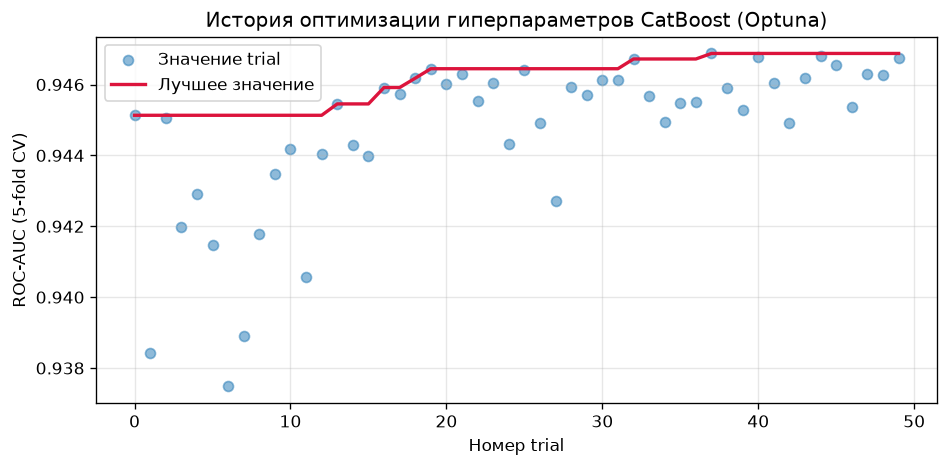

In [38]:
trial_numbers = [t.number for t in study.trials]
trial_values = [t.value for t in study.trials]
running_best = np.maximum.accumulate(trial_values)

fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(trial_numbers, trial_values, alpha=0.5, label="Значение trial")
ax.plot(trial_numbers, running_best, color="crimson", linewidth=2, label="Лучшее значение")
ax.set_xlabel("Номер trial")
ax.set_ylabel("ROC-AUC (5-fold CV)")
ax.set_title("История оптимизации гиперпараметров CatBoost (Optuna)")
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

### Проверка на свежем разбиении кросс-валидации (`cv_seed=2026`)

Оцениваем дефолтный и тюнингованный CatBoost через `run_cv` на новом разбиении `StratifiedKFold(random_state=2026)`, чтобы исключить оптимистичное смещение отбора в Optuna.

In [39]:
CV_SEED_FRESH = 2026

cv_default_2026 = run_cv(build_native_catboost, X_train_final, y_train, cv_seed=CV_SEED_FRESH)
_ = add_result("CatBoost default (cv seed 2026)", cv_default_2026)

cv_tuned_2026 = run_cv(
    lambda: CatBoostClassifier(
        **best_params,
        cat_features=CAT_FEATURES,
        random_seed=RANDOM_STATE,
        verbose=0,
        allow_writing_files=False,
    ),
    X_train_final,
    y_train,
    cv_seed=CV_SEED_FRESH,
)
_ = add_result("CatBoost tuned (cv seed 2026)", cv_tuned_2026)

In [40]:
base_folds_2026 = cv_default_2026["folds"]
tuned_folds_2026 = cv_tuned_2026["folds"]
diff_auc_2026 = tuned_folds_2026["ROC-AUC"] - base_folds_2026["ROC-AUC"]
diff_pr_2026 = tuned_folds_2026["PR-AUC"] - base_folds_2026["PR-AUC"]

step4_rows = []
for label, res in [
    ("CatBoost default (cv seed 2026)", cv_default_2026),
    ("CatBoost tuned (cv seed 2026)", cv_tuned_2026),
]:
    is_tuned = label == "CatBoost tuned (cv seed 2026)"
    step4_rows.append({
        "Модель": label,
        "ROC-AUC (mean ± std)": f"{res['mean']['ROC-AUC']:.4f} ± {res['std']['ROC-AUC']:.4f}",
        "Δ ROC-AUC (paired mean)": f"{diff_auc_2026.mean():+.4f}" if is_tuned else "0.0000",
        "PR-AUC (mean ± std)": f"{res['mean']['PR-AUC']:.4f} ± {res['std']['PR-AUC']:.4f}",
        "Δ PR-AUC (paired mean)": f"{diff_pr_2026.mean():+.4f}" if is_tuned else "0.0000",
        "Фолдов лучше default (ROC-AUC)": f"{int((diff_auc_2026 > 0).sum())}/{N_SPLITS}" if is_tuned else "—",
        "KS (mean ± std)": f"{res['mean']['KS']:.4f} ± {res['std']['KS']:.4f}",
        "Gini (mean ± std)": f"{res['mean']['Gini']:.4f} ± {res['std']['Gini']:.4f}",
    })

step4_comparison_df = pd.DataFrame(step4_rows)
step4_comparison_df

,Модель,ROC-AUC (mean ± std),Δ ROC-AUC (paired mean),PR-AUC (mean ± std),Δ PR-AUC (paired mean),Фолдов лучше default (ROC-AUC),KS (mean ± std),Gini (mean ± std)
0,CatBoost default (cv seed 2026),0.9438 ± 0.0045,0.0000,0.9006 ± 0.0049,0.0000,—,0.7520 ± 0.0090,0.8876 ± 0.0090
1,CatBoost tuned (cv seed 2026),0.9460 ± 0.0048,+0.0022,0.9042 ± 0.0058,+0.0036,5/5,0.7605 ± 0.0080,0.8920 ± 0.0096


**Выводы по тюнингу гиперпараметров:**
- В абсолютном выражении прирост от тюнинга на свежем разбиении (`cv_seed=2026`) невелик — около половины межфолдового `std`, что ожидаемо для табличного датасета из 10 признаков, где эвристики CatBoost по умолчанию уже близки к оптимуму.
- В то же время при попарном сравнении на одних и тех же фолдах более мелкие деревья (`depth=4` вместо `6`) с увеличенным шагом обучения выигрывают у дефолта на каждом из 5 фолдов (`5/5`) как по `ROC-AUC`, так и по `PR-AUC`, `KS` и `Gini`.

In [41]:
BEST_PARAMS = dict(best_params)
BEST_PARAMS

{'depth': 4, 'learning_rate': 0.15248263275183993, 'l2_leaf_reg': 4.743226441772372, 'random_strength': 2.1115768380392548, 'bagging_temperature': 2.6397323786149323, 'border_count': 254, 'iterations': 662}

### Решение по тюнингу

- **Берём `BEST_PARAMS`:** на свежем разбиении (`cv_seed=2026`) прирост `ROC-AUC` составляет около `+0.0022`, `PR-AUC` — около `+0.0036`, и `tuned` лучше `default` на всех 5 фолдах; прирост небольшой, как и ожидалось для этого датасета.
- **Оптимистичность оценки:** параметры подбирались на тех же данных `train`, поэтому честная итоговая оценка прироста будет получена на отложенной выборке `test` в шаге 6.
- **`depth=4` оказался на нижней границе пространства поиска:** расширять сетку вниз не стали, так как ожидаемый дополнительный выигрыш находится в пределах межфолдового шума.

## Шаг 5. Калибровка вероятностей и выбор порога

Решаем две прикладные задачи кредитного скоринга строго на out-of-fold предсказаниях `train`: проверяем калибровку предсказываемых вероятностей дефолта (чтобы прогноз `0.30` соответствовал ~30% фактических дефолтов) и выбираем рабочий порог одобрения исходя из соотношения цен ошибок первого и второго рода.

In [42]:
cv_tuned_oof = run_cv(
    lambda: CatBoostClassifier(
        **BEST_PARAMS,
        cat_features=CAT_FEATURES,
        random_seed=RANDOM_STATE,
        verbose=0,
        allow_writing_files=False,
    ),
    X_train_final,
    y_train,
    cv_seed=RANDOM_STATE,
)
oof_proba = cv_tuned_oof["oof_proba"]

In [43]:
const_proba = np.full_like(oof_proba, fill_value=float(y_train.mean()))

raw_calib_metrics_df = pd.DataFrame([
    {
        "Предсказание": "CatBoost tuned (raw OOF)",
        "Brier score": round(float(brier_score_loss(y_train, oof_proba)), 5),
        "Log loss": round(float(log_loss(y_train, oof_proba)), 5),
    },
    {
        "Предсказание": f"Константа (доля дефолтов = {y_train.mean():.4f})",
        "Brier score": round(float(brier_score_loss(y_train, const_proba)), 5),
        "Log loss": round(float(log_loss(y_train, const_proba)), 5),
    },
])
raw_calib_metrics_df

,Предсказание,Brier score,Log loss
0,CatBoost tuned (raw OOF),0.05253,0.18871
1,Константа (доля дефолтов = 0.2188),0.17091,0.52534


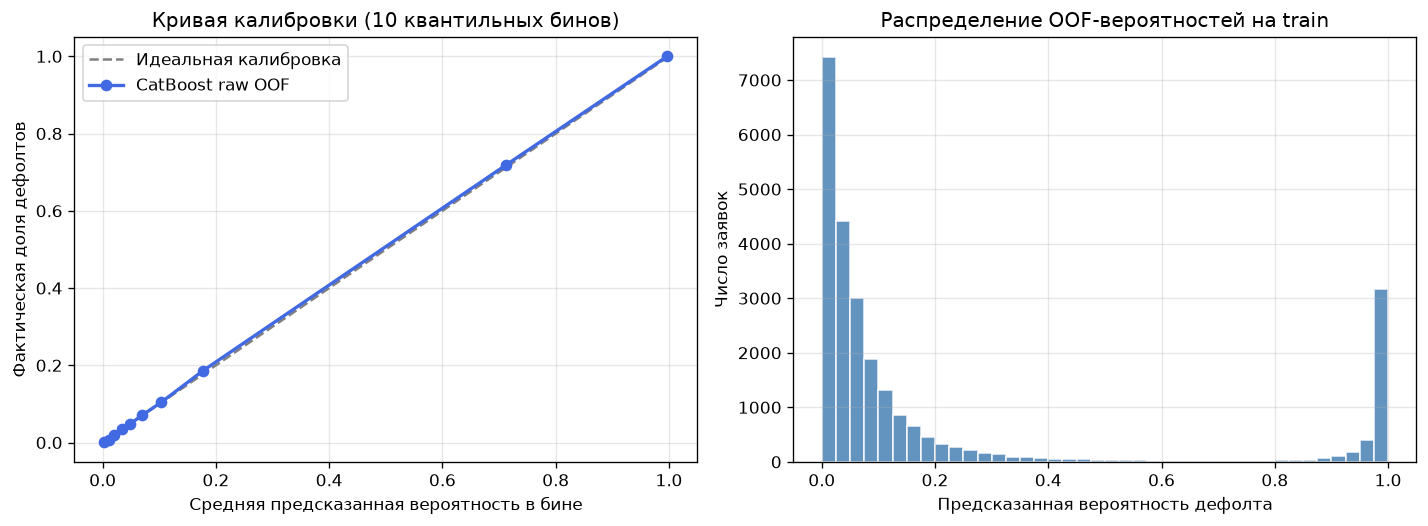

In [44]:
prob_true, prob_pred = calibration_curve(y_train, oof_proba, n_bins=10, strategy="quantile")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

ax1.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Идеальная калибровка")
ax1.plot(prob_pred, prob_true, marker="o", linewidth=2, color="royalblue", label="CatBoost raw OOF")
ax1.set_xlabel("Средняя предсказанная вероятность в бине")
ax1.set_ylabel("Фактическая доля дефолтов")
ax1.set_title("Кривая калибровки (10 квантильных бинов)")
ax1.grid(True, alpha=0.3)
ax1.legend()

ax2.hist(oof_proba, bins=40, color="steelblue", edgecolor="white", alpha=0.85)
ax2.set_xlabel("Предсказанная вероятность дефолта")
ax2.set_ylabel("Число заявок")
ax2.set_title("Распределение OOF-вероятностей на train")
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [45]:
calib_cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)
oof_2d = oof_proba.reshape(-1, 1)

oof_proba_isotonic = cross_val_predict(
    IsotonicRegression(out_of_bounds="clip"),
    oof_2d,
    y_train,
    cv=calib_cv,
    method="predict",
)
oof_proba_sigmoid = cross_val_predict(
    LogisticRegression(random_state=RANDOM_STATE),
    oof_2d,
    y_train,
    cv=calib_cv,
    method="predict_proba",
)[:, 1]

calib_comparison_df = pd.DataFrame([
    {
        "Вариант": name,
        "Brier score": round(float(brier_score_loss(y_train, probs)), 5),
        "Log loss": round(float(log_loss(y_train, probs)), 5),
        "ROC-AUC": round(float(roc_auc_score(y_train, probs)), 4),
    }
    for name, probs in [
        ("raw", oof_proba),
        ("isotonic", oof_proba_isotonic),
        ("sigmoid", oof_proba_sigmoid),
    ]
])
calib_comparison_df

,Вариант,Brier score,Log loss,ROC-AUC
0,raw,0.05253,0.18871,0.9461
1,isotonic,0.05256,0.19095,0.9451
2,sigmoid,0.05415,0.19959,0.9459


**Вывод по калибровке вероятностей:**
- Дополнительная калибровка не нужна: CatBoost обучается с логистической функцией потерь (`Logloss`) и без искусственной перебалансировки классов, поэтому его сырые вероятности (`raw`) уже лежат вплотную к диагонали идеальной калибровки.
- Ни `isotonic`, ни `sigmoid` (Platt) на честной вложенной кросс-валидации не улучшают `Brier score` или `Log loss` по сравнению с `raw` (`sigmoid` заметно ухудшает обе метрики из-за жёсткой логистической формы на скошенном распределении вероятностей), поэтому для подбора порога и в финальной модели оставляем сырые вероятности CatBoost.

In [46]:
final_proba_for_threshold = oof_proba

### Модель цены ошибок и подбор порога отсечения

Вводим асимметричную матрицу потерь: пропуск дефолта (`FN`, выдача кредита неплательщику) обходится банку в `c` условных единиц, тогда как ложный отказ платёжеспособному заёмщику (`FP`, упущенная процентная маржа) стоит `1` единицу. В качестве базового сценария принимаем `c = 5`, а значения `c = 3` и `c = 10` используем для проверки чувствительности порога. Это упрощённая портфельная модель с фиксированным отношением потерь, тогда как в реальном бизнесе стоимость ошибки зависит от суммы конкретного кредита, ставки, срока и уровня возврата при взыскании (`LGD`).

In [47]:
THRESHOLD_GRID = np.round(np.arange(0.01, 1.00, 0.01), 2)


def evaluate_thresholds(
    y_true: pd.Series | np.ndarray,
    proba: np.ndarray,
    cost_fn: float,
    thresholds: np.ndarray = THRESHOLD_GRID,
) -> pd.DataFrame:
    """Считает операционные метрики скоринга и среднюю цену ошибки на заявку по сетке порогов."""
    y_arr = np.asarray(y_true, dtype=int)
    n_total = len(y_arr)
    n_defaults = int(y_arr.sum())
    rows = []

    for thr in thresholds:
        pred_default = proba >= thr
        tp = int(np.sum(pred_default & (y_arr == 1)))
        fp = int(np.sum(pred_default & (y_arr == 0)))
        fn = int(np.sum((~pred_default) & (y_arr == 1)))
        tn = int(np.sum((~pred_default) & (y_arr == 0)))

        approved = tn + fn
        rows.append({
            "threshold": float(thr),
            "approval_rate": approved / n_total,
            "recall": tp / n_defaults if n_defaults > 0 else 0.0,
            "precision": tp / (tp + fp) if (tp + fp) > 0 else 0.0,
            "bad_rate": fn / approved if approved > 0 else 0.0,
            "mean_cost": (cost_fn * fn + 1.0 * fp) / n_total,
        })

    return pd.DataFrame(rows)

In [48]:
COST_VALUES = [3, 5, 10]
cost_grids: dict[int, pd.DataFrame] = {}
threshold_summary_rows = []

for c_val in COST_VALUES:
    grid_df = evaluate_thresholds(y_train, final_proba_for_threshold, cost_fn=c_val)
    cost_grids[c_val] = grid_df
    best_row = grid_df.loc[grid_df["mean_cost"].idxmin()]
    threshold_summary_rows.append({
        "Сценарий": f"Оптимум (c={c_val})",
        "c": c_val,
        "Теор. порог 1/(1+c)": round(1.0 / (1.0 + c_val), 4),
        "Эмп. порог": round(float(best_row["threshold"]), 2),
        "Доля одобрений": round(float(best_row["approval_rate"]), 4),
        "Recall": round(float(best_row["recall"]), 4),
        "Precision": round(float(best_row["precision"]), 4),
        "Bad rate (одобр.)": round(float(best_row["bad_rate"]), 4),
        "Цена на заявку": round(float(best_row["mean_cost"]), 4),
    })

row_05 = cost_grids[5].loc[cost_grids[5]["threshold"] == 0.50].iloc[0]
threshold_summary_rows.append({
    "Сценарий": "Порог 0.50 (при c=5)",
    "c": 5,
    "Теор. порог 1/(1+c)": round(1.0 / (1.0 + 5), 4),
    "Эмп. порог": 0.50,
    "Доля одобрений": round(float(row_05["approval_rate"]), 4),
    "Recall": round(float(row_05["recall"]), 4),
    "Precision": round(float(row_05["precision"]), 4),
    "Bad rate (одобр.)": round(float(row_05["bad_rate"]), 4),
    "Цена на заявку": round(float(row_05["mean_cost"]), 4),
})

threshold_summary_df = pd.DataFrame(threshold_summary_rows)
threshold_summary_df

,Сценарий,c,Теор. порог 1/(1+c),Эмп. порог,Доля одобрений,Recall,Precision,Bad rate (одобр.),Цена на заявку
0,Оптимум (c=3),3,0.2500,0.24,0.7922,0.7956,0.8374,0.0565,0.1680
1,Оптимум (c=5),5,0.1667,0.16,0.7413,0.8432,0.7129,0.0463,0.2458
2,Оптимум (c=10),10,0.0909,0.08,0.5908,0.9222,0.4930,0.0288,0.3776
3,Порог 0.50 (при c=5),5,0.1667,0.50,0.8337,0.7325,0.9638,0.0702,0.2987


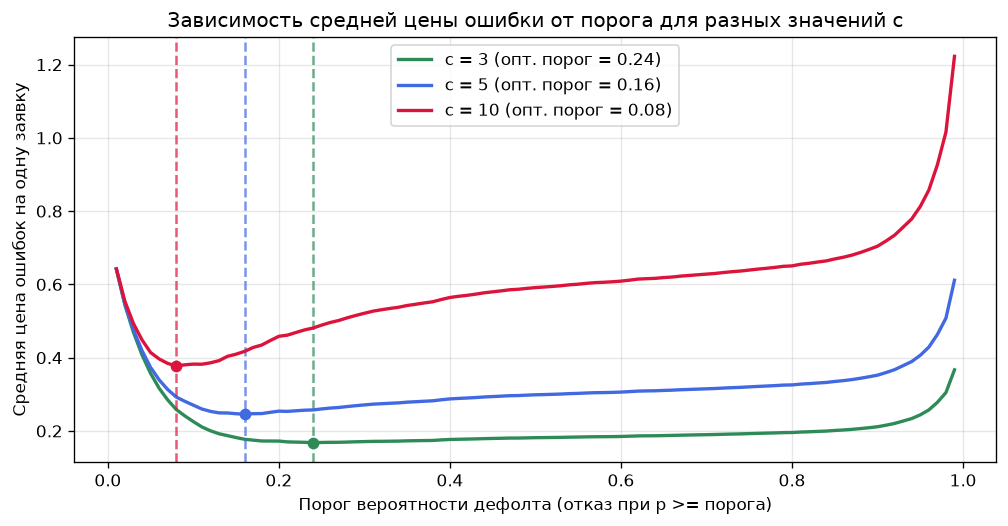

In [49]:
fig, ax = plt.subplots(figsize=(8.5, 4.5))
colors = {3: "seagreen", 5: "royalblue", 10: "crimson"}

for c_val in COST_VALUES:
    grid_df = cost_grids[c_val]
    best_row = grid_df.loc[grid_df["mean_cost"].idxmin()]
    opt_thr = float(best_row["threshold"])
    opt_cost = float(best_row["mean_cost"])

    ax.plot(
        grid_df["threshold"],
        grid_df["mean_cost"],
        linewidth=2,
        color=colors[c_val],
        label=f"c = {c_val} (опт. порог = {opt_thr:.2f})",
    )
    ax.axvline(opt_thr, linestyle="--", color=colors[c_val], alpha=0.7)
    ax.scatter([opt_thr], [opt_cost], color=colors[c_val], zorder=5)

ax.set_xlabel("Порог вероятности дефолта (отказ при p >= порога)")
ax.set_ylabel("Средняя цена ошибок на одну заявку")
ax.set_title("Зависимость средней цены ошибки от порога для разных значений c")
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

**Вывод по выбору порога:**
- Для базового сценария `c = 5` фиксируем рабочий порог **`THRESHOLD = 0.16`**: при таком отсечении банк одобряет около `74%` заявок, отлавливая `84.3%` будущих дефолтов, а доля дефолтов среди выданных кредитов (`bad rate`) снижается с исходных `21.9%` до `4.6%` (тогда как стандартный порог `0.50` пропускает в полтора раза больше дефолтов и даёт на ~22% большую цену ошибки).
- Благодаря хорошей калибровке вероятностей эмпирический оптимум для всех трёх значений `c` практически совпадает с теоретическим порогом Байеса `1 / (1 + c)` с точностью до одного шага сетки (`0.01`).
- Минимум кривой потерь вокруг `0.16` пологий (в диапазоне порогов `0.14–0.19` средняя цена меняется менее чем на `2%`), поэтому выбранный порог устойчив к умеренным колебаниям оценки `c`.

In [50]:
USE_CALIBRATION = False
THRESHOLD = 0.16
print(f"USE_CALIBRATION = {USE_CALIBRATION}, THRESHOLD = {THRESHOLD}")

USE_CALIBRATION = False, THRESHOLD = 0.16


## Шаг 6. Финальная оценка на `test`

Обучаем зафиксированную конфигурацию модели на всём `train` и проводим единственную итоговую проверку на отложенной выборке `test`.
Главное правило: `test` смотрим один раз — после просмотра `test` не меняем признаки, гиперпараметры, порог и калибровку, даже если результат разочарует.

In [51]:
final_model = CatBoostClassifier(
    cat_features=CAT_FEATURES,
    random_seed=RANDOM_STATE,
    verbose=0,
    allow_writing_files=False,
    **BEST_PARAMS,
)
final_model.fit(X_train_final, y_train)

CatBoostClassifier(allow_writing_files=False, bagging_temperature=2.6397323786149323, border_count=254, cat_features=['person_home_ownership', 'loan_intent', 'loan_grade', 'cb_person_default_on_file'], depth=4, iterations=662, l2_leaf_reg=4.743226441772372, learning_rate=0.15248263275183993, random_seed=42, random_strength=2.1115768380392548, verbose=0)

In [52]:
X_test_final = prepare_features(X_test)
test_proba = final_model.predict_proba(X_test_final)[:, 1]

In [53]:
test_metrics = compute_metrics(y_test, test_proba)
test_metrics["Brier score"] = float(brier_score_loss(y_test, test_proba))
test_metrics["Log loss"] = float(log_loss(y_test, test_proba))

pd.Series(test_metrics, name="CatBoost tuned (test)").round(4).to_frame()

,CatBoost tuned (test)
ROC-AUC,0.9486
PR-AUC,0.9115
KS,0.7789
Gini,0.8972
Brier score,0.0488
Log loss,0.1791


In [54]:
logreg_test_model = build_logreg_baseline()
logreg_test_model.fit(preprocess_df(X_train), y_train)
logreg_test_proba = logreg_test_model.predict_proba(preprocess_df(X_test))[:, 1]

cb_default_test_model = build_native_catboost()
cb_default_test_model.fit(X_train_final, y_train)
cb_default_test_proba = cb_default_test_model.predict_proba(X_test_final)[:, 1]

cat_no_grade = [c for c in CAT_FEATURES if c != "loan_grade"]
cb_no_grade_test_model = CatBoostClassifier(
    cat_features=cat_no_grade,
    random_seed=RANDOM_STATE,
    verbose=0,
    allow_writing_files=False,
    **BEST_PARAMS,
)
cb_no_grade_test_model.fit(X_train_final.drop(columns=["loan_grade"]), y_train)
cb_no_grade_test_proba = cb_no_grade_test_model.predict_proba(
    X_test_final.drop(columns=["loan_grade"])
)[:, 1]

In [55]:
test_comparison_df = pd.DataFrame(
    [
        {"Модель": "LogReg baseline", **compute_metrics(y_test, logreg_test_proba)},
        {"Модель": "CatBoost default", **compute_metrics(y_test, cb_default_test_proba)},
        {"Модель": "CatBoost tuned (финальная)", **compute_metrics(y_test, test_proba)},
        {"Модель": "CatBoost tuned без грейда и ставки", **compute_metrics(y_test, cb_no_grade_test_proba)},
    ]
).set_index("Модель")[["ROC-AUC", "PR-AUC", "KS", "Gini"]]

test_comparison_df.round(4)

,ROC-AUC,PR-AUC,KS,Gini
Модель,,,,
LogReg baseline,0.8764,0.7095,0.6031,0.7527
CatBoost default,0.9483,0.9116,0.7811,0.8967
CatBoost tuned (финальная),0.9486,0.9115,0.7789,0.8972
CatBoost tuned без грейда и ставки,0.9113,0.8315,0.6612,0.8226


In [56]:
rng = np.random.default_rng(RANDOM_STATE)
y_test_arr = y_test.to_numpy()
n_test = len(y_test_arr)
boot_roc, boot_pr = [], []

for _ in range(1000):
    idx = rng.integers(0, n_test, size=n_test)
    boot_roc.append(roc_auc_score(y_test_arr[idx], test_proba[idx]))
    boot_pr.append(average_precision_score(y_test_arr[idx], test_proba[idx]))

ci_df = pd.DataFrame(
    [
        {
            "Метрика": "ROC-AUC",
            "Оценка на test": test_metrics["ROC-AUC"],
            "95% CI нижняя": float(np.percentile(boot_roc, 2.5)),
            "95% CI верхняя": float(np.percentile(boot_roc, 97.5)),
        },
        {
            "Метрика": "PR-AUC",
            "Оценка на test": test_metrics["PR-AUC"],
            "95% CI нижняя": float(np.percentile(boot_pr, 2.5)),
            "95% CI верхняя": float(np.percentile(boot_pr, 97.5)),
        },
    ]
).set_index("Метрика")

ci_df.round(4)

,Оценка на test,95% CI нижняя,95% CI верхняя
Метрика,,,
ROC-AUC,0.9486,0.9413,0.9555
PR-AUC,0.9115,0.8998,0.9223


In [57]:
test_pred = (test_proba >= THRESHOLD).astype(int)
cm_counts = confusion_matrix(y_test, test_pred)
cm_norm = confusion_matrix(y_test, test_pred, normalize="true")

cm_table = pd.DataFrame(
    [
        [
            f"{cm_counts[0, 0]} ({cm_norm[0, 0]:.2%})",
            f"{cm_counts[0, 1]} ({cm_norm[0, 1]:.2%})",
        ],
        [
            f"{cm_counts[1, 0]} ({cm_norm[1, 0]:.2%})",
            f"{cm_counts[1, 1]} ({cm_norm[1, 1]:.2%})",
        ],
    ],
    index=["Факт: 0 (без дефолта)", "Факт: 1 (дефолт)"],
    columns=["Прогноз: 0 (одобрить)", "Прогноз: 1 (отказать)"],
)

tn, fp, fn, tp = cm_counts.ravel()
op_summary = pd.Series(
    {
        "Доля одобрений (approval rate)": (tn + fn) / len(y_test),
        "Recall по дефолтам": tp / (tp + fn),
        "Precision по дефолтам": tp / (tp + fp),
        "Доля дефолтов среди одобренных (bad rate)": fn / (tn + fn),
    },
    name=f"Операционные метрики (THRESHOLD = {THRESHOLD})",
).round(4)

display(cm_table)
display(op_summary.to_frame())

,Прогноз: 0 (одобрить),Прогноз: 1 (отказать)
Факт: 0 (без дефолта),4599 (90.85%),463 (9.15%)
Факт: 1 (дефолт),201 (14.17%),1217 (85.83%)


,Операционные метрики (THRESHOLD = 0.16)
Доля одобрений (approval rate),0.7407
Recall по дефолтам,0.8583
Precision по дефолтам,0.7244
Доля дефолтов среди одобренных (bad rate),0.0419


In [58]:
cost_rows = []
for c_val in [3, 5, 10]:
    thr_eval = evaluate_thresholds(
        y_test, test_proba, cost_fn=c_val, thresholds=np.array([THRESHOLD, 0.50])
    ).set_index("threshold")
    cost_016 = float(thr_eval.loc[THRESHOLD, "mean_cost"])
    cost_050 = float(thr_eval.loc[0.50, "mean_cost"])
    cost_rows.append(
        {
            "c (цена FN к FP)": c_val,
            "Цена на заявку (порог 0.16)": round(cost_016, 4),
            "Цена на заявку (порог 0.50)": round(cost_050, 4),
            "Разница (0.16 − 0.50)": round(cost_016 - cost_050, 4),
        }
    )

pd.DataFrame(cost_rows).set_index("c (цена FN к FP)")

,Цена на заявку (порог 0.16),Цена на заявку (порог 0.50),Разница (0.16 − 0.50)
c (цена FN к FP),,,
3,0.1645,0.1696,-0.0051
5,0.2265,0.2804,-0.0539
10,0.3816,0.5574,-0.1758


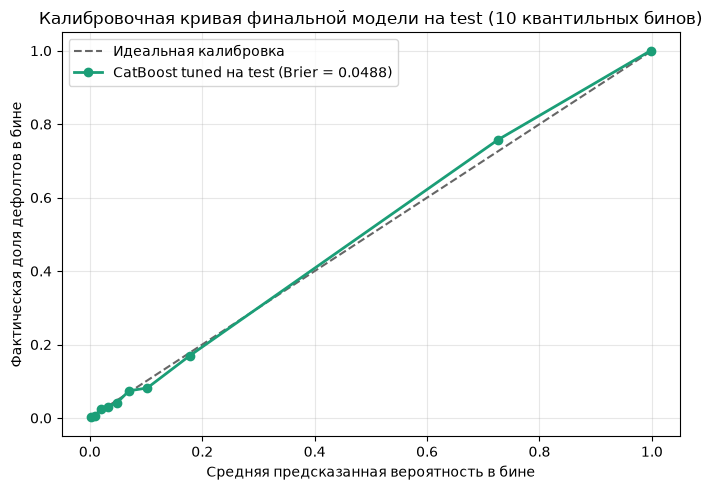

In [59]:
prob_true_test, prob_pred_test = calibration_curve(
    y_test, test_proba, n_bins=10, strategy="quantile"
)

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot([0, 1], [0, 1], "--", color="#666666", label="Идеальная калибровка")
ax.plot(
    prob_pred_test,
    prob_true_test,
    marker="o",
    linewidth=2,
    color="#1b9e77",
    label=f"CatBoost tuned на test (Brier = {test_metrics['Brier score']:.4f})",
)
ax.set_xlabel("Средняя предсказанная вероятность в бине")
ax.set_ylabel("Фактическая доля дефолтов в бине")
ax.set_title("Калибровочная кривая финальной модели на test (10 квантильных бинов)")
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

**Вывод по финальной оценке на `test`:**
- Метрики на отложенной выборке полностью согласуются с кросс-валидацией на `train`: `ROC-AUC` на `test` составил `0.9486` против `0.9460` на чистой CV `train` (разница `+0.0026`), при этом CV-оценка уверенно лежит внутри 95% бутстрап-интервала на `test` (`[0.9413, 0.9555]`), то есть переобучения под `train` нет.
- Сырые вероятности CatBoost сохранили отличную калибровку на `test` (`Brier score = 0.0488`, `Log loss = 0.1791`, точки всех 10 квантильных бинов лежат вдоль диагонали), что подтверждает решение не применять посткалибровку.
- Рабочий порог `THRESHOLD = 0.16` удержал целевые операционные характеристики (`74.1%` одобрений, `recall = 85.8%`, `bad rate` среди одобренных `4.2%`) и снижает среднюю цену ошибки на заявку при `c = 5` на `19%` по сравнению со стандартным порогом `0.50`.

## Шаг 7. Интерпретация и итог

С помощью `SHAP` разбираем глобальную структуру решений финальной модели и локальные вклады признаков: какие факторы и в какую сторону сдвигают оценку вероятности дефолта.
Прозрачная интерпретация необходима как для аудита кредитного портфеля и проверки бизнес-логики скоринга, так и для предметного объяснения причин отказа конкретному заёмщику.

In [60]:
explainer = shap.TreeExplainer(final_model)
test_pool = Pool(X_test_final, cat_features=CAT_FEATURES)
shap_values = explainer.shap_values(test_pool)
expected_value = float(explainer.expected_value)

print(f"Размер матрицы shap_values: {shap_values.shape}, базовый логит expected_value: {expected_value:.4f}")

Размер матрицы shap_values: (6480, 10), базовый логит expected_value: -1.8431


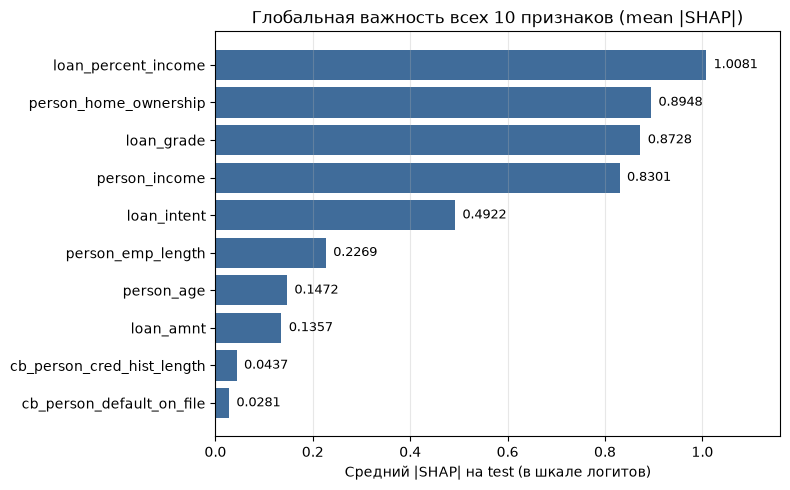

In [61]:
mean_abs_shap = (
    pd.Series(np.abs(shap_values).mean(axis=0), index=X_test_final.columns)
    .sort_values(ascending=True)
)

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.barh(mean_abs_shap.index, mean_abs_shap.values, color="#2b5c8f", alpha=0.9)
for bar, val in zip(bars, mean_abs_shap.values):
    ax.text(val + 0.015, bar.get_y() + bar.get_height() / 2, f"{val:.4f}", va="center", fontsize=9)
ax.set_xlim(0, float(mean_abs_shap.max()) * 1.15)
ax.set_xlabel("Средний |SHAP| на test (в шкале логитов)")
ax.set_title("Глобальная важность всех 10 признаков (mean |SHAP|)")
ax.grid(True, axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

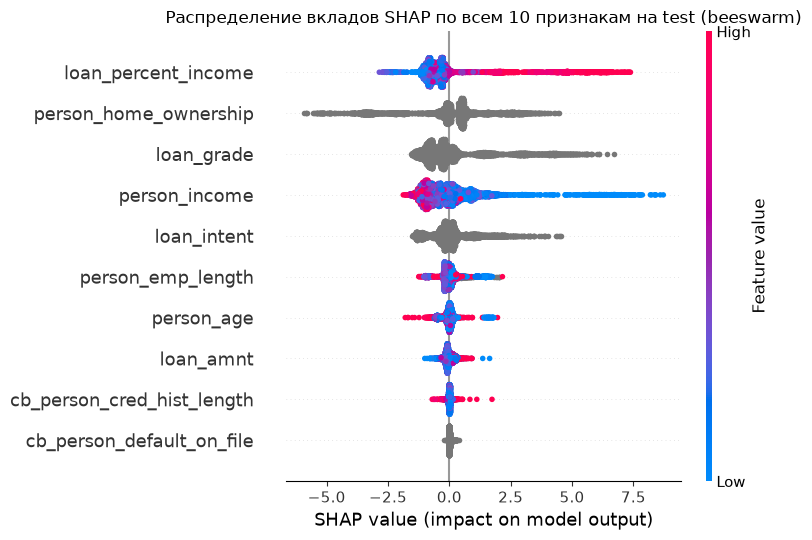

In [62]:
plt.figure(figsize=(9, 5.5))
shap.summary_plot(
    shap_values,
    X_test_final,
    max_display=10,
    show=False,
)
plt.title("Распределение вкладов SHAP по всем 10 признакам на test (beeswarm)")
plt.tight_layout()
plt.show()

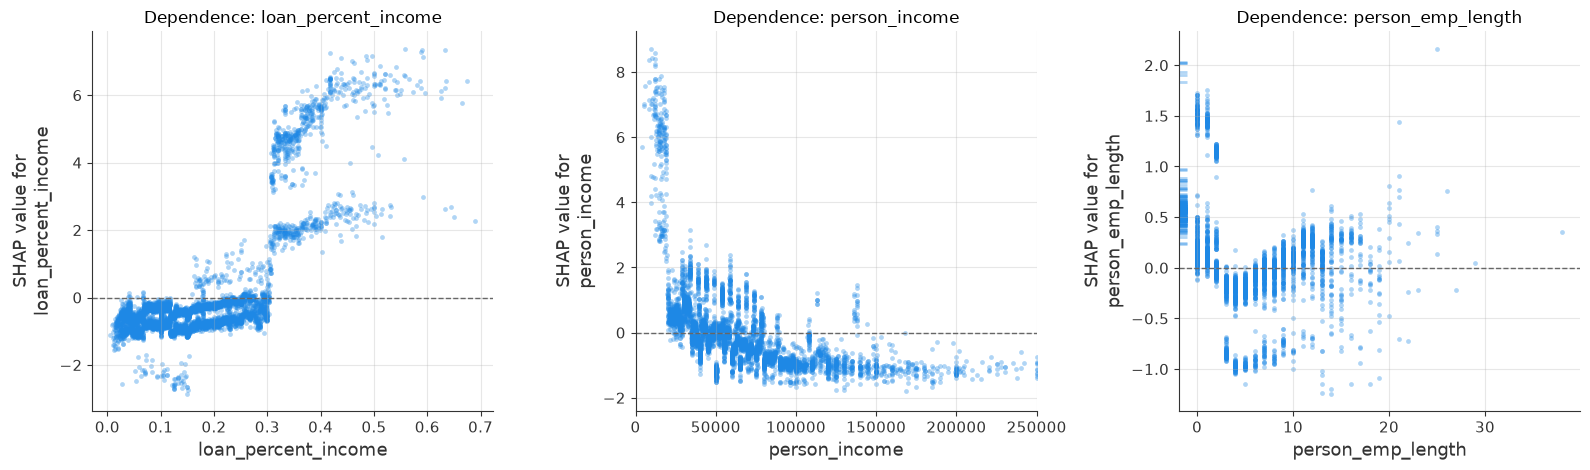

In [63]:
top3_num_features = ["loan_percent_income", "person_income", "person_emp_length"]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for ax, feat in zip(axes, top3_num_features):
    shap.dependence_plot(
        feat,
        shap_values,
        X_test_final,
        interaction_index=None,
        ax=ax,
        alpha=0.35,
        dot_size=12,
        show=False,
    )
    ax.axhline(0.0, color="#666666", linestyle="--", linewidth=1)
    ax.set_title(f"Dependence: {feat}")
    ax.grid(True, alpha=0.3)

axes[1].set_xlim(0, 250000)
plt.tight_layout()
plt.show()

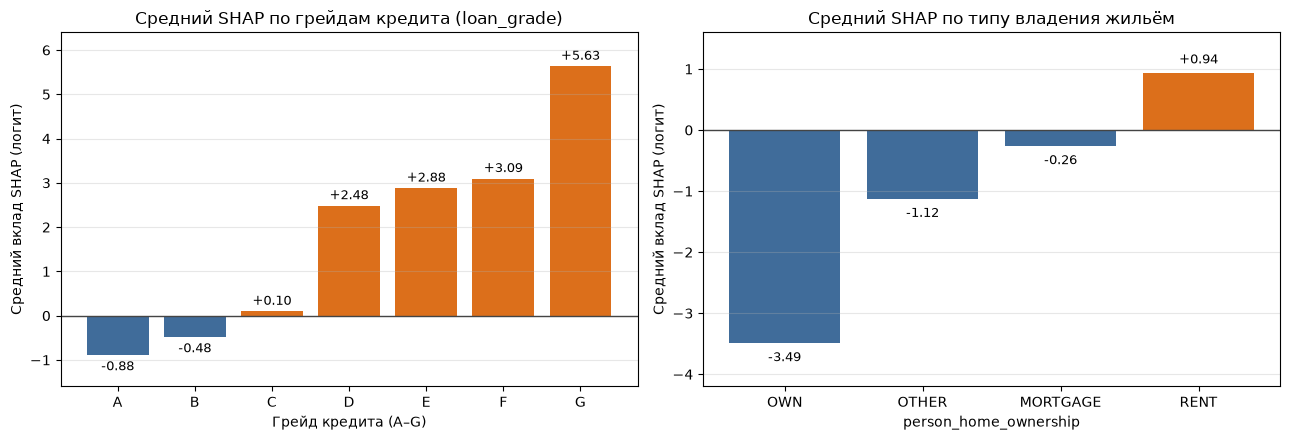

In [64]:
grade_idx = X_test_final.columns.get_loc("loan_grade")
home_idx = X_test_final.columns.get_loc("person_home_ownership")

grade_shap_df = (
    pd.DataFrame({"loan_grade": X_test_final["loan_grade"], "shap": shap_values[:, grade_idx]})
    .groupby("loan_grade")["shap"]
    .agg(count="count", mean_shap="mean")
    .reindex(["A", "B", "C", "D", "E", "F", "G"])
)

home_shap_df = (
    pd.DataFrame({"person_home_ownership": X_test_final["person_home_ownership"], "shap": shap_values[:, home_idx]})
    .groupby("person_home_ownership")["shap"]
    .agg(count="count", mean_shap="mean")
    .sort_values("mean_shap")
)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

colors_grade = ["#2b5c8f" if v < 0 else "#d95f02" for v in grade_shap_df["mean_shap"]]
bars_g = axes[0].bar(grade_shap_df.index, grade_shap_df["mean_shap"], color=colors_grade, alpha=0.9)
axes[0].axhline(0.0, color="#444444", linewidth=1)
axes[0].set_title("Средний SHAP по грейдам кредита (loan_grade)")
axes[0].set_xlabel("Грейд кредита (A–G)")
axes[0].set_ylabel("Средний вклад SHAP (логит)")
axes[0].grid(True, axis="y", alpha=0.3)
for b, v in zip(bars_g, grade_shap_df["mean_shap"]):
    offset = 0.15 if v >= 0 else -0.35
    axes[0].text(b.get_x() + b.get_width() / 2, v + offset, f"{v:+.2f}", ha="center", fontsize=9)
axes[0].set_ylim(-1.6, 6.4)

colors_home = ["#2b5c8f" if v < 0 else "#d95f02" for v in home_shap_df["mean_shap"]]
bars_h = axes[1].bar(home_shap_df.index, home_shap_df["mean_shap"], color=colors_home, alpha=0.9)
axes[1].axhline(0.0, color="#444444", linewidth=1)
axes[1].set_title("Средний SHAP по типу владения жильём")
axes[1].set_xlabel("person_home_ownership")
axes[1].set_ylabel("Средний вклад SHAP (логит)")
axes[1].grid(True, axis="y", alpha=0.3)
for b, v in zip(bars_h, home_shap_df["mean_shap"]):
    offset = 0.15 if v >= 0 else -0.30
    axes[1].text(b.get_x() + b.get_width() / 2, v + offset, f"{v:+.2f}", ha="center", fontsize=9)
axes[1].set_ylim(-4.2, 1.6)

plt.tight_layout()
plt.show()

Отказанная заявка вблизи порога (proba > 0.16): test_index=24296, proba=0.2015 (порог 0.16)
Одобренная заявка вблизи порога (proba < 0.16): test_index=790, proba=0.1215 (порог 0.16)


,Значение,SHAP (логит)
Признак,,
loan_grade,D,1.5602
person_home_ownership,MORTGAGE,-0.7489
loan_intent,EDUCATION,-0.3909
person_emp_length,1.0000,0.3632
person_income,72000,-0.2847


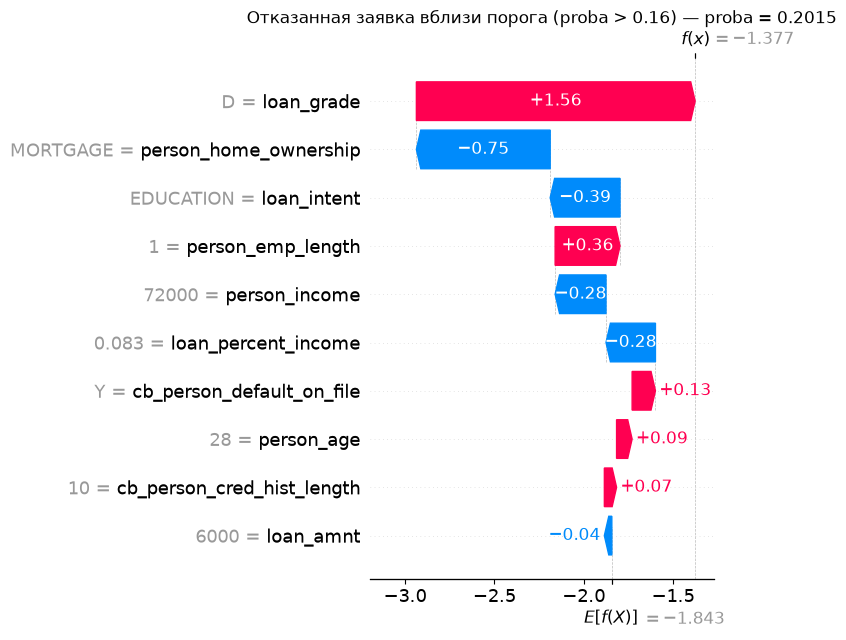

,Значение,SHAP (логит)
Признак,,
person_income,22000,0.5134
loan_percent_income,0.1739,-0.3677
loan_grade,B,-0.3318
loan_intent,DEBTCONSOLIDATION,0.2555
person_emp_length,3.0000,-0.2044


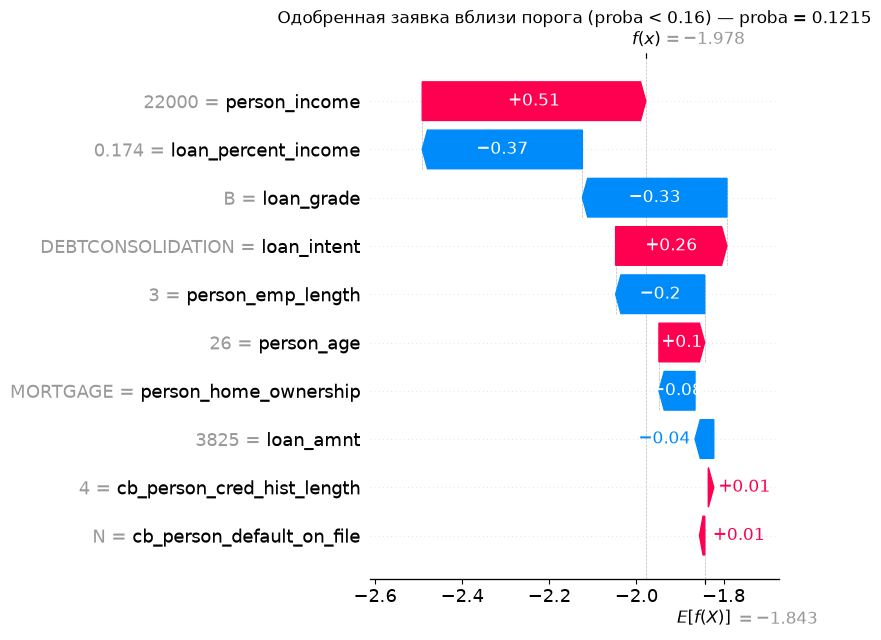

In [65]:
rejected_pos = int(np.where((test_proba >= 0.19) & (test_proba <= 0.21))[0][0])
approved_pos = int(np.where((test_proba >= 0.11) & (test_proba <= 0.13))[0][0])

for case_label, pos in [
    ("Отказанная заявка вблизи порога (proba > 0.16)", rejected_pos),
    ("Одобренная заявка вблизи порога (proba < 0.16)", approved_pos),
]:
    row_vals = X_test_final.iloc[pos]
    row_shap = shap_values[pos]
    top5_factors = (
        pd.DataFrame({
            "Признак": X_test_final.columns,
            "Значение": [f"{v:.4f}" if isinstance(v, float) else str(v) for v in row_vals.values],
            "SHAP (логит)": np.round(row_shap, 4),
            "|SHAP|": np.round(np.abs(row_shap), 4),
        })
        .sort_values("|SHAP|", ascending=False)
        .head(5)
        .set_index("Признак")[["Значение", "SHAP (логит)"]]
    )
    print(f"{case_label}: test_index={X_test_final.index[pos]}, proba={test_proba[pos]:.4f} (порог {THRESHOLD})")
    display(top5_factors)

    expl_obj = shap.Explanation(
        values=row_shap,
        base_values=expected_value,
        data=row_vals.values,
        feature_names=list(X_test_final.columns),
    )
    plt.figure(figsize=(8, 4.2))
    shap.plots.waterfall(expl_obj, max_display=10, show=False)
    plt.title(f"{case_label} — proba = {test_proba[pos]:.4f}")
    plt.tight_layout()
    plt.show()

**Вывод по глобальной интерпретации модели:**
- **Топ-3 признака по среднему `|SHAP|`:** `loan_percent_income` (`1.008`), `person_home_ownership` (`0.895`) и `loan_grade` (`0.873`), за которыми вплотную следует `person_income` (`0.830`); на эту четвёрку приходится более `77%` суммарного абсолютного вклада всех признаков.
- **Направление влияния:** риск дефолта резко растёт при превышении долговой нагрузкой `loan_percent_income` порога `~0.25–0.30` от годового дохода, при аренде жилья (`RENT`, в отличие от собственного жилья `OWN`, сильно снижающего риск) и при ухудшении грейда с `A–B` до `D–G`; рост дохода `person_income` монотонно снижает риск.
- **Проверка на аномалии:** зависимости по ключевым факторам полностью согласуются с кредитной логикой; единственная неочевидная деталь видна на `dependence`-графике `person_emp_length` — минимальный риск достигается при стаже `3–6` лет, тогда как на правом хвосте (`> 8–10` лет) вклад `SHAP` слегка поднимается чуть выше нуля (причины этого из самого графика неочевидны).

### Спецификация модели (`MODEL_SPEC`) для переноса в `src/`

Собираем в единый словарь контракт входных признаков, правила подготовки данных, гиперпараметры, порог отсечения, контрольные метрики на `test` и версии библиотек.

In [66]:
MODEL_SPEC: dict[str, Any] = {
    "model_name": "CatBoostClassifier (native categorical + recomputed loan_percent_income)",
    "input_features_before_prepare": {
        col: str(dtype) for col, dtype in X_train.dtypes.items()
    },
    "api_input_features": {
        "person_age": "int",
        "person_income": "int",
        "person_home_ownership": "str",
        "person_emp_length": "float | None",
        "loan_intent": "str",
        "loan_grade": "str",
        "loan_amnt": "int",
        "cb_person_default_on_file": "str",
        "cb_person_cred_hist_length": "int",
    },
    "dropped_columns": DROP_COLS,
    "derived_features": {
        "loan_percent_income": "loan_amnt / person_income",
    },
    "model_features": list(X_train_final.columns),
    "cat_features": CAT_FEATURES,
    "best_params": BEST_PARAMS,
    "random_seed": RANDOM_STATE,
    "use_calibration": USE_CALIBRATION,
    "threshold": THRESHOLD,
    "cost_assumption": {
        "fn_to_fp_cost_ratio_c": 5,
        "fp_cost": 1.0,
        "fn_cost": 5.0,
        "bayes_theoretical_threshold": round(1.0 / (1.0 + 5), 4),
    },
    "test_metrics": {
        "ROC-AUC": round(test_metrics["ROC-AUC"], 4),
        "PR-AUC": round(test_metrics["PR-AUC"], 4),
        "KS": round(test_metrics["KS"], 4),
        "Gini": round(test_metrics["Gini"], 4),
        "Brier_score": round(test_metrics["Brier score"], 4),
        "Log_loss": round(test_metrics["Log loss"], 4),
    },
    "versions": {
        "python": platform.python_version(),
        "catboost": catboost.__version__,
        "scikit-learn": sklearn.__version__,
        "pandas": pd.__version__,
        "numpy": np.__version__,
        "shap": shap.__version__,
    },
}

print(json.dumps(MODEL_SPEC, ensure_ascii=False, indent=2))

{
  "model_name": "CatBoostClassifier (native categorical + recomputed loan_percent_income)",
  "input_features_before_prepare": {
    "person_age": "int64",
    "person_income": "int64",
    "person_home_ownership": "str",
    "person_emp_length": "float64",
    "loan_intent": "str",
    "loan_grade": "str",
    "loan_amnt": "int64",
    "loan_int_rate": "float64",
    "loan_percent_income": "float64",
    "cb_person_default_on_file": "str",
    "cb_person_cred_hist_length": "int64"
  },
  "api_input_features": {
    "person_age": "int",
    "person_income": "int",
    "person_home_ownership": "str",
    "person_emp_length": "float | None",
    "loan_intent": "str",
    "loan_grade": "str",
    "loan_amnt": "int",
    "cb_person_default_on_file": "str",
    "cb_person_cred_hist_length": "int"
  },
  "dropped_columns": [
    "loan_int_rate"
  ],
  "derived_features": {
    "loan_percent_income": "loan_amnt / person_income"
  },
  "model_features": [
    "person_age",
    "person_income

## Итог ноутбука

- **Что сравнивали и что выбрали:** в серии контролируемых экспериментов на 5-fold CV (`train = 25 918` строк) сопоставили линейный бейзлайн и конфигурации `CatBoost` по составу признаков, способу подачи категорий и пропусков, генерации новых признаков, тюнингу гиперпараметров (`Optuna`, 50 trials) и методам калибровки.
- **Финальная конфигурация:** `CatBoostClassifier` на 10 признаках без `loan_int_rate`, с пересчётом `loan_percent_income = loan_amnt / person_income`, нативной подачей 4 строковых категорий (`CAT_FEATURES`) и пропусков `person_emp_length`, гиперпараметрами `BEST_PARAMS` (`depth = 4`, `iterations = 662`, `learning_rate ≈ 0.1525`), без посткалибровки (`USE_CALIBRATION = False`) и с порогом отказа `THRESHOLD = 0.16`.
- **Главные результаты на отложенной выборке `test` (`6 480` строк):** `ROC-AUC = 0.9486` (95% ДИ `[0.9413, 0.9555]`), `PR-AUC = 0.9115` (95% ДИ `[0.8998, 0.9223]`), `KS = 0.7789`, `Gini = 0.8972`, `Brier score = 0.0488`; при пороге `0.16` одобряется `74.1%` заявок, отсекается `85.8%` дефолтов, а доля дефолтов среди одобренных снижается с `21.9%` до `4.2%`.
- **Ключевые факторы риска по `SHAP`:** решение модели определяется прежде всего долговой нагрузкой `loan_percent_income`, типом владения жильём `person_home_ownership`, кредитным грейдом `loan_grade` и уровнем дохода `person_income`.
- **Честные оговорки и ограничения:**
  1. Тюнинг гиперпараметров и ручной feature engineering дали минимальный выигрыш относительно дефолтного `CatBoost` (`+0.0003` `ROC-AUC` на `test`), хотя позволили уменьшить глубину и число деревьев.
  2. Существенная часть разделяющей способности (`~0.037` `ROC-AUC` на `test`) опирается на внутренний банковский грейд `loan_grade`; при этом даже без грейда и ставки бустинг сохраняет высокое качество (`ROC-AUC = 0.9113`).
  3. Работа выполнена на учебном статическом датасете без временной разметки (`out-of-time` валидация невозможна), а рабочий порог `0.16` напрямую привязан к модельному допущению об отношении цены пропуска дефолта к ложному отказу `c = 5`.